## Análisis de Datos Meteorológicos con una API Pública
Obtener datos del clima de una ciudad usando la API de Open-Meteo (https://open-meteo.com/) y mostrar el pronóstico para Bilbao.

* Haz una petición a la API para que devuelva el pronóstico de las temperaturas para una semana en Bilbao. Tip: el parámetro correspondiente en el query es `temperature_2m` además de la latitud y la longitud.
* Procesa la respuesta en formato JSON para obtener dos listas: una con la lista de temperaturas y otra con las fechas-horas correspondientes.
* Crea un DataFrame con esas dos columnas: `Hora` y `Temperatura`
* Elige la gráfica adecuada y visualiza el pronóstico de temperaturas.

Para crear la variable `Hora` del DataFrame puedes introducir directamente la lista que se obtiene del campo `data["hourly"]["time"]` o procesar esa lista mediante el siguiente código:

`hours = pd.date_range(start=lista_de_horas, periods=len(temps), freq="H")`

In [1]:
import requests


# Coordenadas de Kuna en Bilbao
latitude = 43.2540
longitude = -2.9230


url = f"https://api.open-meteo.com/v1/forecast?latitude=43.2540&longitude=-2.9230&hourly=temperature_2m"  # Aquí vienen el resto de los parámetros

In [2]:
response = requests.get(url)

In [3]:
response.json()

{'latitude': 43.25,
 'longitude': -2.92,
 'generationtime_ms': 0.06186962127685547,
 'utc_offset_seconds': 0,
 'timezone': 'GMT',
 'timezone_abbreviation': 'GMT',
 'elevation': 14.0,
 'hourly_units': {'time': 'iso8601', 'temperature_2m': '°C'},
 'hourly': {'time': ['2026-11-06T00:00',
   '2026-11-06T01:00',
   '2026-11-06T02:00',
   '2026-11-06T03:00',
   '2026-11-06T04:00',
   '2026-11-06T05:00',
   '2026-11-06T06:00',
   '2026-11-06T07:00',
   '2026-11-06T08:00',
   '2026-11-06T09:00',
   '2026-11-06T10:00',
   '2026-11-06T11:00',
   '2026-11-06T12:00',
   '2026-11-06T13:00',
   '2026-11-06T14:00',
   '2026-11-06T15:00',
   '2026-11-06T16:00',
   '2026-11-06T17:00',
   '2026-11-06T18:00',
   '2026-11-06T19:00',
   '2026-11-06T20:00',
   '2026-11-06T21:00',
   '2026-11-06T22:00',
   '2026-11-06T23:00',
   '2026-11-07T00:00',
   '2026-11-07T01:00',
   '2026-11-07T02:00',
   '2026-11-07T03:00',
   '2026-11-07T04:00',
   '2026-11-07T05:00',
   '2026-11-07T06:00',
   '2026-11-07T07:00',
 

In [4]:
# Procesa la respuesta en formato JSON para obtener dos listas: una con la lista de temperaturas y otra con las fechas-horas correspondientes.
data = response.json()

temperaturas = data["hourly"]["temperature_2m"]
horas = data["hourly"]["time"]

In [5]:
# Crea un DataFrame con esas dos columnas: `Hora` y `Temperatura`

import pandas as pd

weather = pd.DataFrame({"Hora": horas, "Temperatura": temperaturas})

In [6]:
weather.head()

,Hora,Temperatura
0,2026-11-06T00:00,8.6
1,2026-11-06T01:00,8.2
2,2026-11-06T02:00,7.8
3,2026-11-06T03:00,7.6
4,2026-11-06T04:00,7.4


In [7]:
weather

,Hora,Temperatura
0,2026-11-06T00:00,8.6
1,2026-11-06T01:00,8.2
2,2026-11-06T02:00,7.8
3,2026-11-06T03:00,7.6
4,2026-11-06T04:00,7.4
...,...,...
163,2026-11-12T19:00,14.3
164,2026-11-12T20:00,14.1
165,2026-11-12T21:00,14.0
166,2026-11-12T22:00,14.0


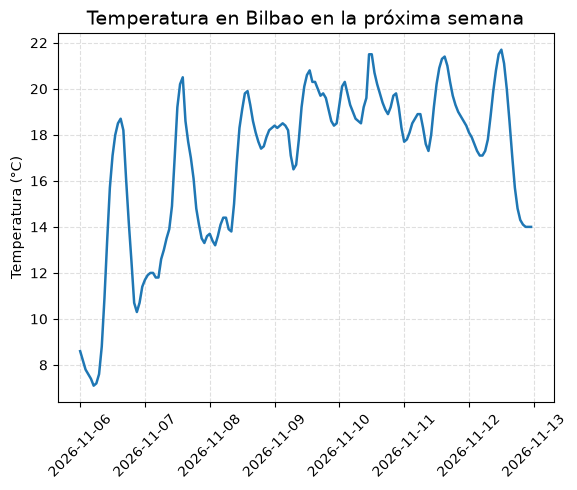

In [10]:
import matplotlib.pyplot as plt

weather1 = weather.copy()

weather1['Hora'] = pd.to_datetime(weather1['Hora'])


plt.plot(
    weather1['Hora'],
    weather1['Temperatura'],
    linewidth=1.8
)

plt.title('Temperatura en Bilbao en la próxima semana', fontsize=14)
plt.ylabel('Temperatura (°C)', fontsize=10)


plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.4)

plt.show()

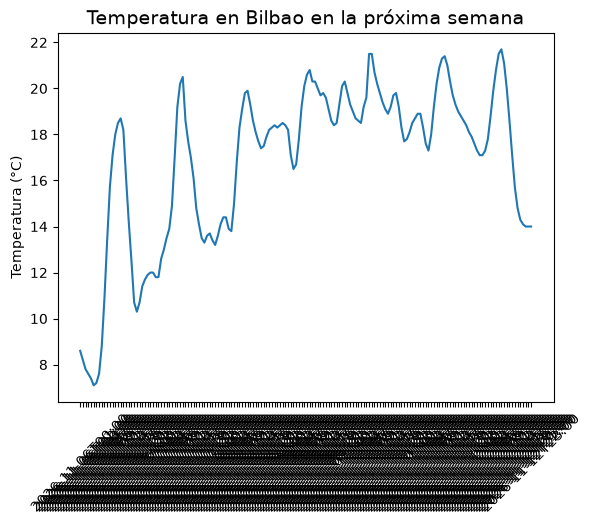

In [9]:
plt.plot(
    weather["Hora"],
    weather["Temperatura"]
)

plt.title('Temperatura en Bilbao en la próxima semana', fontsize=14)
plt.ylabel('Temperatura (°C)', fontsize=10)
plt.xticks(rotation=45)

plt.show()